# Avance 2: Ingeniería de Características (PASTIS Dataset)

**Dataset:** PASTIS (series temporales Sentinel-2 + máscaras semánticas de parcelas agrícolas)  
**Marco de trabajo:** CRISP-ML(Q) — fase de *Data Preparation*  
**Equipo:** 13 · **Entrega:** 11 de octubre de 2026

---

## Tabla de contenidos
1. **Configuración, hardware y carga del dataset** (KaggleHub, GPU)
2. **Construcción de características** — índices espectrales (NDVI, NDWI, NDMI, NDRE, NBR, EVI), agregaciones robustas, fenología, discretización y codificación
3. **Normalización y transformación** — asimetría (Yeo-Johnson), estandarización y estadísticas por banda para modelos profundos
4. **Selección y extracción** — varianza → correlación guiada por ANOVA → $\chi^2$/Cramér para categóricas → selección de *k* con validación → PCA
5. **Validación del beneficio** (MLP en GPU + Random Forest)
6. **Exportación** del pipeline ajustado y las particiones
7. **Conclusiones CRISP-ML(Q)**

### Principio rector: sin fuga de datos (*data leakage*)
Todos los transformadores (imputador, discretizador, Yeo-Johnson, escalador, selección, PCA) se **ajustan solo con el conjunto de entrenamiento** y luego se aplican a validación y prueba. Las particiones usan los **folds oficiales de PASTIS** (separados espacialmente) cuando `metadata.json` está disponible.

In [ ]:
   import torch
   m = torch.nn.Linear(3, 2)
   torch.optim.Adam(m.parameters())
   print("torch ok", torch.__version__)
   !df -h /

torch ok 2.11.0+cu130
Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   80G   34G  71% /


In [ ]:
# ==============================================================================
# 1. CONFIGURACIÓN DEL ENTORNO, HARDWARE Y LIBRERÍAS
# ==============================================================================
# !pip install -q kagglehub     # (descomentar si kagglehub no está instalado)
import os, re, json, pickle, time, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from tqdm.auto import tqdm
from IPython.display import display, Markdown

import torch
import torch.nn as nn
import kagglehub

from sklearn.preprocessing import PowerTransformer, StandardScaler, MinMaxScaler, KBinsDiscretizer, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, f_classif
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score

# Reproducibilidad y estilo
SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED); torch.manual_seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette("Set2")
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)

print("--- Verificación de Hardware ---")
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
    print(f"✅ PyTorch detectó GPU: {torch.cuda.get_device_name(0)}")
else:
    DEVICE = torch.device('cpu')
    print("⚠️ PyTorch ejecutando en CPU (activa GPU: Entorno de ejecución > Cambiar tipo > T4 GPU).")
print("✅ Entorno cargado exitosamente.")

--- Verificación de Hardware ---
✅ PyTorch detectó GPU: Tesla T4
✅ Entorno cargado exitosamente.


In [ ]:
# ==============================================================================
# PARÁMETROS DEL EXPERIMENTO (todas las decisiones numéricas en un solo lugar)
# ==============================================================================
DATASET_SLUG = "a01634782/pastis"          # slug de Kaggle del dataset del equipo

N_PARCHES = {'train': 120, 'val': 40, 'test': 40}   # parches muestreados por partición
MAX_PX_CLASE_PARCHE = 40     # tope de píxeles por clase y por parche (muestreo estratificado por clase)
UMBRAL_NUBE_B02 = 0.25       # reflectancia en azul (B02) > 0.25 => observación nubosa/brillante (heurística)
MIN_OBS_VALIDAS = 5          # mínimo de observaciones temporales válidas por píxel

UMBRAL_VARIANZA = 0.005      # VarianceThreshold sobre variables llevadas a [0, 1] (Min-Max)
UMBRAL_SKEW = 0.75           # |asimetría| a partir de la cual se aplica Yeo-Johnson
UMBRAL_CORR = 0.90           # |r| de Pearson a partir de la cual dos variables se consideran redundantes
UMBRAL_CRAMER = 0.10         # V de Cramér mínimo (efecto pequeño) para conservar una categórica
N_CLASES = 18                # clases agrícolas 1..18  -> índices 0..17

In [ ]:
# ==============================================================================
# CARGA DEL DATASET E INVENTARIO (continuidad del Avance 1)
# ==============================================================================
path = kagglehub.dataset_download(DATASET_SLUG)
print("Dataset verificado en:", path)

# Emparejamiento de archivos S2 y TARGET mediante regex (+ localizar metadata.json)
s2_dict, target_dict, meta_path = {}, {}, None
for root, dirs, files in os.walk(path):
    for file in files:
        full_path = os.path.join(root, file)
        m = re.search(r"S2_(\d+)\.npy$", file)
        if m: s2_dict[int(m.group(1))] = full_path
        m = re.search(r"TARGET_(\d+)\.npy$", file)
        if m: target_dict[int(m.group(1))] = full_path
        if file == 'metadata.json': meta_path = full_path

ids_comunes = sorted(set(s2_dict) & set(target_dict))
print(f"🔍 Total de parches emparejados (S2 + TARGET): {len(ids_comunes)}")
print(f"📄 metadata.json: {meta_path}")

# Diccionarios de referencia oficial de PASTIS
CLASES = {
    0: "Background", 1: "Meadow", 2: "Soft winter wheat", 3: "Corn", 4: "Winter barley",
    5: "Winter rapeseed", 6: "Spring barley", 7: "Sunflower", 8: "Grapevine", 9: "Beet",
    10: "Winter triticale", 11: "Winter durum wheat", 12: "Fruits/veg/flowers",
    13: "Potatoes", 14: "Leguminous fodder", 15: "Soybeans", 16: "Orchard",
    17: "Mixed cereal", 18: "Sorghum", 19: "Void label"
}
BANDAS = ["B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B11", "B12"]
IDX = {b: i for i, b in enumerate(BANDAS)}

Dataset verificado en: /root/.cache/kagglehub/datasets/a01634782/pastis/versions/1
🔍 Total de parches emparejados (S2 + TARGET): 2433
📄 metadata.json: None


In [ ]:
# ==============================================================================
# METADATOS: FOLDS OFICIALES Y FECHAS DE ADQUISICIÓN
# ==============================================================================
META = {}
if meta_path:
    try:
        with open(meta_path) as f:
            raw = json.load(f)
        feats = raw['features'] if isinstance(raw, dict) and 'features' in raw else raw
        for ft in feats:
            p = ft.get('properties', ft)
            META[int(p['ID_PATCH'])] = {'fold': p.get('Fold'), 'dates': p.get('dates-S2')}
    except Exception as e:
        print("⚠️ No se pudo interpretar metadata.json:", e); META = {}

HAY_FOLDS = bool(META) and all(META.get(i, {}).get('fold') is not None for i in ids_comunes)
HAY_FECHAS = bool(META) and all(bool(META.get(i, {}).get('dates')) for i in ids_comunes)
print(f"Folds oficiales disponibles: {HAY_FOLDS} | Fechas S2 disponibles: {HAY_FECHAS}")

# --- Particiones: folds oficiales (espacialmente separados) o, si no hay metadata, aleatoria por parche ---
if HAY_FOLDS:
    fold_de = {i: int(META[i]['fold']) for i in ids_comunes}
    FOLDS_SPLIT = {'train': [1, 2, 3], 'val': [4], 'test': [5]}
    ids_split = {s: [i for i in ids_comunes if fold_de[i] in fs] for s, fs in FOLDS_SPLIT.items()}
else:
    fold_de = {}
    perm = [int(i) for i in rng.permutation(ids_comunes)]
    a, b = int(0.6 * len(perm)), int(0.8 * len(perm))
    ids_split = {'train': perm[:a], 'val': perm[a:b], 'test': perm[b:]}
    print("⚠️ Se usa partición aleatoria por parche (no hay folds oficiales).")

# Muestra reproducible de parches por partición (la partición se hace por PARCHE, nunca por píxel)
ids_muestra = {s: sorted(int(i) for i in rng.choice(ids, size=min(N_PARCHES[s], len(ids)), replace=False))
               for s, ids in ids_split.items()}
display(pd.DataFrame({'parches_disponibles': {s: len(v) for s, v in ids_split.items()},
                      'parches_muestreados': {s: len(v) for s, v in ids_muestra.items()}}))

Folds oficiales disponibles: False | Fechas S2 disponibles: False
⚠️ Se usa partición aleatoria por parche (no hay folds oficiales).


,parches_disponibles,parches_muestreados
train,1459,120
val,487,40
test,487,40


## 2. Construcción de características (Feature Engineering)

### Justificación técnica y agronómica
Cada píxel de PASTIS es una **serie temporal** de 10 bandas Sentinel-2. Los cultivos se distinguen por **cuándo** y **cuánto** reverdecen (fenología), no por una reflectancia puntual. Por eso construimos descriptores que conservan esa información.

**1. Reescalamiento físico y limpieza de observaciones.** Se divide entre 10 000 para trabajar en reflectancia $[0,1]$. Una observación se marca como **inválida** (NaN) si hay *no-data* (reflectancia $\leq 0$) o es brillante en azul ($B02 > 0.25$, heurística de nubes). En el Avance 1 y en la inspección previa aparecieron NDVI $>1$ y NDWI con desviaciones enormes: esos valores son imposibles físicamente y se deben a denominadores ≈ 0. Los índices se **recortan a $[-1,1]$** y se anulan cuando $|{\rm denominador}| < 10^{-6}$.

**2. Índices espectrales** (cada uno responde a una propiedad distinta):

| Índice | Fórmula | Qué mide |
|---|---|---|
| NDVI | $\frac{B08-B04}{B08+B04}$ | Biomasa fotosintéticamente activa |
| EVI | $2.5\frac{B08-B04}{B08+6B04-7.5B02+1}$ | Vigor vegetal corregido por suelo/atmósfera (no se satura en dosel denso) |
| NDRE | $\frac{B8A-B05}{B8A+B05}$ | Contenido de clorofila / nitrógeno (borde rojo) |
| NDMI | $\frac{B08-B11}{B08+B11}$ | **Humedad de la vegetación** (NIR–SWIR) |
| NBR | $\frac{B08-B12}{B08+B12}$ | Estructura/senescencia y suelo desnudo (SWIR2) |
| NDWI | $\frac{B03-B08}{B03+B08}$ | **Agua abierta** (McFeeters); se conserva por contraste con NDMI |

> Nota: NDWI (verde–NIR) detecta agua superficial; la humedad del dosel se mide con NDMI (NIR–SWIR). Por eso se incluyen ambos y la selección posterior decidirá cuál aporta.

**3. Agregación temporal robusta.** Se usa la **mediana** (no la media) y percentiles P10/P90 porque son resistentes a nubes residuales; se añade desviación estándar y amplitud (máx − mín) del NDVI como medida de dinamismo del cultivo.

**4. Fenología.** `dia_pico_ndvi` (día del año del máximo NDVI), `estacion_pico` (estación del pico, **categórica nominal**) y el NDVI medio por estación (invierno, primavera, verano, otoño). Distingue, p. ej., cereal de invierno (pico en primavera) de maíz/girasol (pico en verano).

**5. Discretización (binning) y codificación.**
- *Ordinal:* `ndvi_mediana_cat` y `ndvi_amplitud_cat` mediante **cuantiles (3 bins)** ajustados en entrenamiento: evita umbrales arbitrarios y aporta robustez a *outliers*. Tiene orden natural → codificación ordinal.
- *One-hot:* `estacion_pico` es nominal (sin orden) → *one-hot*.
- *Etiqueta:* `clase_id` (1–18) se remapea a índices contiguos 0–17 requeridos por las funciones de pérdida.

**6. Muestreo.** Se filtran las clases no agrícolas (Background=0, Void=19) y se toman hasta 40 píxeles **por clase y por parche**, para que las clases minoritarias no queden diluidas por *Meadow*. Todo el cálculo se hace **vectorizado en GPU** con PyTorch.

In [ ]:
# ==============================================================================
# FUNCIONES DE CONSTRUCCIÓN DE CARACTERÍSTICAS (GPU, vectorizado por parche)
# ==============================================================================
MES_A_ESTACION = {12: 0, 1: 0, 2: 0, 3: 1, 4: 1, 5: 1, 6: 2, 7: 2, 8: 2, 9: 3, 10: 3, 11: 3}
NOMBRES_ESTACION = ['invierno', 'primavera', 'verano', 'otono'] if HAY_FECHAS else ['T1', 'T2', 'T3', 'T4']

def info_temporal(pid, T):
    # Devuelve (día del año, estación 0-3) por observación; None si las fechas no cuadran con T.
    if HAY_FECHAS:
        d = META[pid]['dates']
        vals = [d[k] for k in sorted(d, key=lambda k: int(k))] if isinstance(d, dict) else list(d)
        if len(vals) != T:
            return None
        fechas = pd.to_datetime([str(v) for v in vals], format='%Y%m%d')
        doy = fechas.dayofyear.values.astype(np.float32)
        est = np.array([MES_A_ESTACION[m] for m in fechas.month], dtype=np.int64)
    else:  # sin fechas: posición relativa en la serie, dividida en cuartiles
        doy = np.arange(T, dtype=np.float32)
        est = np.minimum((np.arange(T) * 4) // T, 3).astype(np.int64)
    return doy, est

def nanstd_t(x):
    m = torch.nanmean(x, dim=0, keepdim=True)
    return torch.sqrt(torch.nanmean((x - m) ** 2, dim=0))

def nanmax_t(x):
    r = torch.where(torch.isnan(x), torch.full_like(x, -float('inf')), x).max(dim=0).values
    return torch.where(torch.isinf(r), torch.full_like(r, float('nan')), r)

def nanmin_t(x):
    r = torch.where(torch.isnan(x), torch.full_like(x, float('inf')), x).min(dim=0).values
    return torch.where(torch.isinf(r), torch.full_like(r, float('nan')), r)

def calcular_features(px, doy, est, dev=DEVICE):
    # px: (T, 10, n) reflectancia [0,1]. Devuelve dict de arrays (n,) con las características.
    x = torch.from_numpy(px).to(dev)
    B = {b: x[:, IDX[b], :] for b in BANDAS}
    nan_t = torch.full_like(B['B02'], float('nan'))

    # Observación válida: sin no-data y sin brillo de nube en azul
    valido = ((B['B02'] > 0) & (B['B03'] > 0) & (B['B04'] > 0) & (B['B08'] > 0) & (B['B11'] > 0)
              & (B['B02'] < UMBRAL_NUBE_B02))
    enm = lambda t: torch.where(valido, t, nan_t)

    def idx_nd(a, b):  # diferencia normalizada acotada a [-1, 1]
        den = a + b
        malo = den.abs() < 1e-6
        r = (a - b) / torch.where(malo, torch.ones_like(den), den)
        return enm(torch.where(malo, nan_t, r.clamp(-1, 1)))

    ndvi = idx_nd(B['B08'], B['B04'])
    ndwi = idx_nd(B['B03'], B['B08'])
    ndmi = idx_nd(B['B08'], B['B11'])
    ndre = idx_nd(B['B8A'], B['B05'])
    nbr  = idx_nd(B['B08'], B['B12'])
    den_evi = B['B08'] + 6.0 * B['B04'] - 7.5 * B['B02'] + 1.0
    evi = enm(torch.where(den_evi.abs() < 1e-3, nan_t, (2.5 * (B['B08'] - B['B04']) / torch.where(den_evi.abs() < 1e-3, torch.ones_like(den_evi), den_evi)).clamp(-1, 1)))

    f = {}
    # --- NDVI: estadísticos robustos y de dinamismo ---
    q = torch.nanquantile(ndvi, torch.tensor([0.1, 0.9], device=dev), dim=0)
    f['ndvi_mediana'] = torch.nanmedian(ndvi, dim=0).values
    f['ndvi_std'] = nanstd_t(ndvi)
    f['ndvi_max'] = nanmax_t(ndvi)
    f['ndvi_min'] = nanmin_t(ndvi)
    f['ndvi_amplitud'] = f['ndvi_max'] - f['ndvi_min']
    f['ndvi_p10'], f['ndvi_p90'] = q[0], q[1]
    # --- Resto de índices: mediana y desviación ---
    for nombre, serie in [('ndwi', ndwi), ('ndmi', ndmi), ('ndre', ndre), ('nbr', nbr), ('evi', evi)]:
        f[f'{nombre}_mediana'] = torch.nanmedian(serie, dim=0).values
        f[f'{nombre}_std'] = nanstd_t(serie)
    # --- Bandas espectrales: mediana temporal sobre observaciones válidas ---
    for b in BANDAS:
        f[f'{b}_mediana'] = torch.nanmedian(enm(B[b]), dim=0).values
    # --- Fenología ---
    doy_t, est_t = torch.from_numpy(doy).to(dev), torch.from_numpy(est).to(dev)
    n_val = (~torch.isnan(ndvi)).sum(dim=0)
    lleno = torch.where(torch.isnan(ndvi), torch.full_like(ndvi, -float('inf')), ndvi)
    i_pico = lleno.argmax(dim=0)
    sin_dato = n_val == 0
    f['dia_pico_ndvi'] = torch.where(sin_dato, torch.full_like(doy_t[i_pico], float('nan')), doy_t[i_pico])
    est_pico = est_t[i_pico].float()
    f['est_pico'] = torch.where(sin_dato, torch.full_like(est_pico, float('nan')), est_pico)
    for s in range(4):
        sel = est_t == s
        f[f'ndvi_{NOMBRES_ESTACION[s]}'] = (torch.nanmean(ndvi[sel], dim=0) if bool(sel.any())
                                            else torch.full((ndvi.shape[1],), float('nan'), device=dev))
    f['n_obs_validas'] = n_val.float()
    return {k: v.detach().cpu().numpy() for k, v in f.items()}

def seleccionar_pixeles(tg, max_por_clase):
    # Muestreo estratificado por clase agrícola (1..18) dentro de un parche
    hs, ws = [], []
    for c in range(1, N_CLASES + 1):
        h, w = np.where(tg == c)
        if len(h) == 0: continue
        if len(h) > max_por_clase:
            k = rng.choice(len(h), max_por_clase, replace=False); h, w = h[k], w[k]
        hs.append(h); ws.append(w)
    if not hs: return None
    return np.concatenate(hs), np.concatenate(ws)

def construir_dataset(ids, nombre_split):
    tablas, omitidos = [], 0
    for pid in tqdm(ids, desc=f"Extrayendo características [{nombre_split}]"):
        tg = np.asarray(np.load(target_dict[pid], mmap_mode='r')[0])
        sel = seleccionar_pixeles(tg, MAX_PX_CLASE_PARCHE)
        if sel is None: continue
        hs, ws = sel
        s2 = np.load(s2_dict[pid], mmap_mode='r')                     # (T, 10, H, W)
        px = np.asarray(s2[:, :, hs, ws], dtype=np.float32) / 10000.0  # (T, 10, n): solo lee los píxeles necesarios
        temporal = info_temporal(pid, px.shape[0])
        if temporal is None:
            omitidos += 1; continue
        feats = calcular_features(px, *temporal)
        df = pd.DataFrame(feats)
        df['clase_id'] = tg[hs, ws].astype(int); df['patch_id'] = pid; df['split'] = nombre_split
        tablas.append(df)
    if omitidos: print(f"⚠️ {omitidos} parches omitidos (fechas no coinciden con T).")
    return pd.concat(tablas, ignore_index=True)

In [ ]:
# ==============================================================================
# EXTRACCIÓN DE CARACTERÍSTICAS PARA TRAIN / VAL / TEST
# ==============================================================================
t0 = time.time()
RAW = {s: construir_dataset(ids_muestra[s], s) for s in ['train', 'val', 'test']}
print(f"⏱️ Extracción completada en {time.time() - t0:.1f} s en {DEVICE}")

CLASE_A_IDX = {c: c - 1 for c in range(1, N_CLASES + 1)}
for s, df in RAW.items():
    df = df[df['n_obs_validas'] >= MIN_OBS_VALIDAS].copy()          # calidad: mínimo de observaciones válidas
    df['clase_idx'] = df['clase_id'].map(CLASE_A_IDX).astype(int)
    df['estacion_pico'] = df['est_pico'].map(lambda v: NOMBRES_ESTACION[int(v)])
    RAW[s] = df.reset_index(drop=True)

META_COLS = ['clase_id', 'clase_idx', 'patch_id', 'split', 'n_obs_validas', 'est_pico', 'estacion_pico']
COLS_NUM = [c for c in RAW['train'].columns if c not in META_COLS]
print({s: df.shape for s, df in RAW.items()})
print(f"✨ {len(COLS_NUM)} características numéricas + 1 categórica nominal (estacion_pico)")
display(RAW['train'].head())

Extrayendo características [train]:   0%|          | 0/120 [00:00<?, ?it/s]

Extrayendo características [val]:   0%|          | 0/40 [00:00<?, ?it/s]

Extrayendo características [test]:   0%|          | 0/40 [00:00<?, ?it/s]

⏱️ Extracción completada en 3.2 s en cuda
{'train': (27813, 39), 'val': (8473, 39), 'test': (8990, 39)}
✨ 32 características numéricas + 1 categórica nominal (estacion_pico)


,ndvi_mediana,ndvi_std,ndvi_max,ndvi_min,ndvi_amplitud,ndvi_p10,ndvi_p90,ndwi_mediana,ndwi_std,ndmi_mediana,ndmi_std,ndre_mediana,ndre_std,nbr_mediana,nbr_std,evi_mediana,evi_std,B02_mediana,B03_mediana,B04_mediana,B05_mediana,B06_mediana,B07_mediana,B08_mediana,B8A_mediana,B11_mediana,B12_mediana,dia_pico_ndvi,est_pico,ndvi_T1,ndvi_T2,ndvi_T3,ndvi_T4,n_obs_validas,clase_id,patch_id,split,clase_idx,estacion_pico
0,0.612711,0.148762,0.935646,0.243738,0.691907,0.457016,0.818665,-0.614420,0.120004,0.237490,0.133681,0.500475,0.095458,0.433775,0.145761,0.391644,0.124879,0.0440,0.0653,0.0645,0.0968,0.2245,0.2753,0.2848,0.3098,0.1872,0.1166,16.0,1.0,0.675687,0.689230,0.636567,0.487820,29.0,1,10002,train,0,T2
1,0.690637,0.200171,0.926482,0.301138,0.625343,0.342041,0.886661,-0.629784,0.139419,0.227525,0.188525,0.489101,0.118871,0.477199,0.220622,0.485659,0.183746,0.0373,0.0682,0.0572,0.1115,0.2719,0.3076,0.3403,0.3499,0.2045,0.1169,18.0,1.0,0.519979,0.723204,0.586424,0.781091,29.0,1,10002,train,0,T2
2,0.651914,0.202296,0.977827,0.132584,0.845243,0.370154,0.893371,-0.637116,0.157401,0.108173,0.201274,0.463029,0.140085,0.388145,0.205865,0.336001,0.175401,0.0248,0.0487,0.0371,0.0817,0.1789,0.2090,0.2016,0.2493,0.1630,0.0937,9.0,0.0,0.636076,0.808206,0.571035,0.645567,30.0,1,10002,train,0,T1
3,0.739951,0.166802,0.944338,0.287931,0.656407,0.508662,0.914877,-0.720930,0.134425,0.174094,0.159964,0.549981,0.108805,0.471861,0.177439,0.403001,0.188965,0.0212,0.0404,0.0293,0.0697,0.1800,0.2093,0.2380,0.2380,0.1492,0.0854,22.0,2.0,0.653915,0.816879,0.730937,0.763347,28.0,1,10002,train,0,T3
4,0.757370,0.138549,0.910825,0.359164,0.551660,0.518360,0.866048,-0.694585,0.130927,0.222986,0.123355,0.527697,0.088390,0.456526,0.143979,0.425601,0.141128,0.0263,0.0498,0.0335,0.0848,0.1989,0.2253,0.2657,0.2678,0.1717,0.0958,16.0,1.0,0.749871,0.755789,0.649378,0.736701,28.0,1,10002,train,0,T2


,min,max,%NaN
ndvi_mediana,0.099,0.907,0.000
ndvi_max,0.249,1.000,0.000
ndvi_min,-0.945,0.679,0.000
ndvi_p10,0.005,0.781,0.000
ndvi_p90,0.185,0.985,0.000
ndwi_mediana,-0.835,-0.188,0.000
ndmi_mediana,-0.240,0.525,0.000
ndre_mediana,0.086,0.678,0.000
nbr_mediana,-0.124,0.763,0.000
evi_mediana,0.071,0.754,0.000


✅ Todos los índices dentro de [-1, 1]: True
Valores faltantes totales en train: 1 (0.00%) -> se imputarán con la mediana de entrenamiento


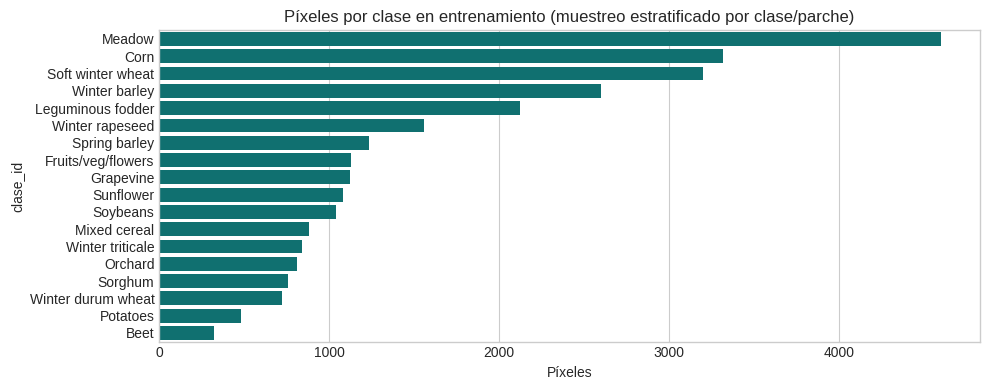

Razón de desbalance (máx/mín): 14.4x -> se usarán pesos de clase al entrenar.


In [ ]:
# ==============================================================================
# CONTROL DE CALIDAD: rangos válidos, valores faltantes y balance de clases
# ==============================================================================
tr = RAW['train']
cols_indices = [c for c in COLS_NUM if c.startswith(('ndvi', 'ndwi', 'ndmi', 'ndre', 'nbr', 'evi'))
                and not c.endswith(('_std', '_amplitud'))]            # valores de índice (rango físico [-1, 1])
calidad = pd.DataFrame({'min': tr[cols_indices].min(), 'max': tr[cols_indices].max(),
                        '%NaN': tr[cols_indices].isna().mean() * 100}).round(3)
display(calidad)
print("✅ Todos los índices dentro de [-1, 1]:", bool((calidad['min'] >= -1).all() and (calidad['max'] <= 1).all()))
print(f"Valores faltantes totales en train: {tr[COLS_NUM].isna().sum().sum()} "
      f"({tr[COLS_NUM].isna().mean().mean() * 100:.2f}%) -> se imputarán con la mediana de entrenamiento")

conteo = tr['clase_id'].map(CLASES).value_counts()
plt.figure(figsize=(10, 4)); sns.barplot(x=conteo.values, y=conteo.index, color='teal')
plt.title("Píxeles por clase en entrenamiento (muestreo estratificado por clase/parche)"); plt.xlabel("Píxeles"); plt.tight_layout(); plt.show()
print(f"Razón de desbalance (máx/mín): {conteo.max() / conteo.min():.1f}x -> se usarán pesos de clase al entrenar.")

### 2.1 Imputación, discretización y codificación (ajustadas solo con *train*)
- **Imputación por mediana** de los pocos NaN restantes (píxeles con pocas observaciones válidas en alguna estación): la mediana es robusta a *outliers*.
- **Discretización por cuantiles** (3 bins, orden natural bajo/medio/alto).
- **One-hot** para `estacion_pico`. El *Cramér's V* (más adelante) decidirá si estas categóricas aportan información sobre la clase.

In [ ]:
# ==============================================================================
# IMPUTACIÓN + DISCRETIZACIÓN ORDINAL + ONE-HOT (fit en train, transform en todos)
# ==============================================================================
SPLITS = ['train', 'val', 'test']
D = {s: RAW[s].copy() for s in SPLITS}

imputer = SimpleImputer(strategy='median').fit(D['train'][COLS_NUM])
for s in SPLITS:
    D[s][COLS_NUM] = imputer.transform(D[s][COLS_NUM])

# Discretización ordinal por cuantiles (umbrales aprendidos solo con train)
COLS_BIN = ['ndvi_mediana', 'ndvi_amplitud']
COLS_BIN_CAT = [c + '_cat' for c in COLS_BIN]
kbd = KBinsDiscretizer(n_bins=3, encode='ordinal', strategy='quantile').fit(D['train'][COLS_BIN])
for s in SPLITS:
    D[s][COLS_BIN_CAT] = kbd.transform(D[s][COLS_BIN]).astype(int)
print("Bordes de los bins (cuantiles de train):", {c: np.round(e, 3).tolist() for c, e in zip(COLS_BIN, kbd.bin_edges_)})

# One-hot de la variable nominal
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(D['train'][['estacion_pico']])
COLS_OHE = [f"estacion_pico_{c}" for c in ohe.categories_[0]]
for s in SPLITS:
    D[s][COLS_OHE] = ohe.transform(D[s][['estacion_pico']])
display(D['train'][COLS_BIN + COLS_BIN_CAT + ['estacion_pico'] + COLS_OHE].head())

Bordes de los bins (cuantiles de train): {'ndvi_mediana': [0.099, 0.367, 0.543, 0.907], 'ndvi_amplitud': [0.19, 0.711, 0.814, 1.872]}


,ndvi_mediana,ndvi_amplitud,ndvi_mediana_cat,ndvi_amplitud_cat,estacion_pico,estacion_pico_T1,estacion_pico_T2,estacion_pico_T3,estacion_pico_T4
0,0.612711,0.691907,2,0,T2,0.0,1.0,0.0,0.0
1,0.690637,0.625343,2,0,T2,0.0,1.0,0.0,0.0
2,0.651914,0.845243,2,2,T1,1.0,0.0,0.0,0.0
3,0.739951,0.656407,2,0,T3,0.0,0.0,1.0,0.0
4,0.757370,0.551660,2,0,T2,0.0,1.0,0.0,0.0


## 3. Normalización, escalamiento y transformación

### Decisiones y justificación
1. **El umbral de varianza se evalúa antes de estandarizar.** Tras un `StandardScaler` todas las variables tienen varianza 1, por lo que `VarianceThreshold` no descartaría nada (era un defecto de la versión anterior). Para que las varianzas sean comparables entre variables con unidades distintas (reflectancia, índices, día del año) se usa una versión **Min-Max $[0,1]$** solo para ese filtro.
2. **Yeo-Johnson solo donde hay asimetría.** Se calcula la asimetría (*skewness*) de **todas** las variables y se transforman las que cumplen $|\text{skew}| > 0.75$. Yeo-Johnson (a diferencia de Box-Cox) admite valores negativos y ceros, necesario para índices en $[-1,1]$.
3. **Estandarización final (`StandardScaler`).** PCA, el ANOVA/correlación y las redes neuronales son sensibles a la escala; estandarizar da a todas las variables un impacto equitativo y acelera la convergencia del gradiente. (Los árboles no lo necesitan, pero tampoco se perjudican.)
4. **Estadísticas por banda** (media/desv. por canal sobre *train*) para normalizar los tensores crudos $(T,10,H,W)$ *on-the-fly* en un `DataLoader` de PyTorch para modelos profundos.

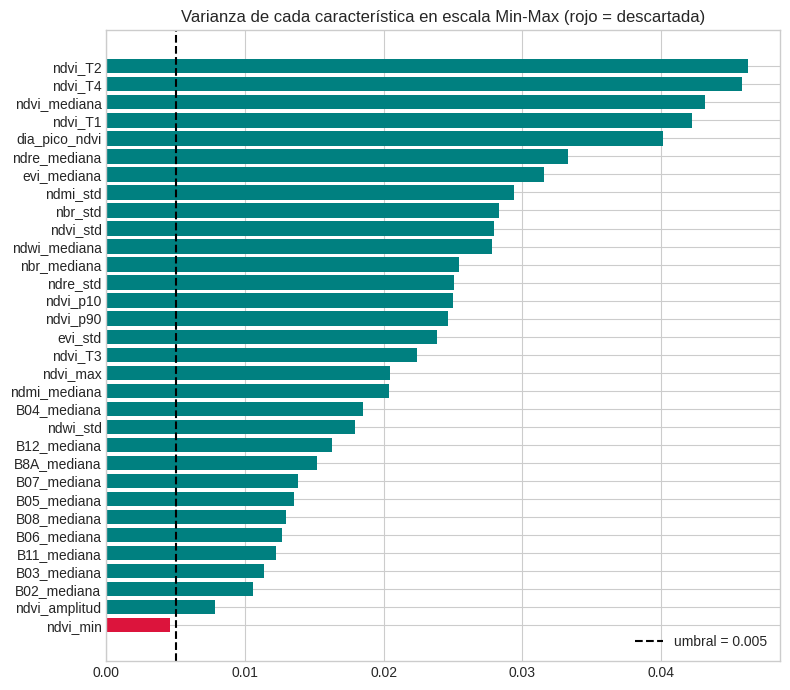

🔹 Retenidas por varianza: 31 de 32
   Descartadas: ['ndvi_min']


In [ ]:
# ==============================================================================
# A. FILTRO DE VARIANZA (sobre variables en escala Min-Max [0,1], solo train)
# ==============================================================================
mm = MinMaxScaler().fit(D['train'][COLS_NUM])
Xmm_tr = mm.transform(D['train'][COLS_NUM])
vt = VarianceThreshold(UMBRAL_VARIANZA).fit(Xmm_tr)
var_tab = (pd.DataFrame({'caracteristica': COLS_NUM, 'varianza_minmax': Xmm_tr.var(axis=0), 'conservada': vt.get_support()})
           .sort_values('varianza_minmax').reset_index(drop=True))
COLS_VAR = [c for c, k in zip(COLS_NUM, vt.get_support()) if k]
descartadas_var = [c for c in COLS_NUM if c not in COLS_VAR]

plt.figure(figsize=(8, 7))
colores = ['crimson' if not k else 'teal' for k in var_tab['conservada']]
plt.barh(var_tab['caracteristica'], var_tab['varianza_minmax'], color=colores)
plt.axvline(UMBRAL_VARIANZA, color='k', ls='--', label=f'umbral = {UMBRAL_VARIANZA}')
plt.title("Varianza de cada característica en escala Min-Max (rojo = descartada)"); plt.legend(); plt.tight_layout(); plt.show()
print(f"🔹 Retenidas por varianza: {len(COLS_VAR)} de {len(COLS_NUM)}")
print("   Descartadas:", descartadas_var if descartadas_var else "ninguna (todas superan el umbral)")

Variables con |asimetría| > 0.75: 6 de 31


,skew_antes,skew_despues,yeo_johnson
ndvi_max,-1.71,-0.28,True
ndvi_p90,-1.27,-0.23,True
B02_mediana,1.13,-0.00,True
B03_mediana,1.03,-0.03,True
ndvi_p10,0.99,0.14,True
B12_mediana,0.96,0.02,True
B11_mediana,0.69,0.69,False
B05_mediana,0.68,0.68,False
evi_mediana,0.67,0.67,False
B04_mediana,0.59,0.59,False


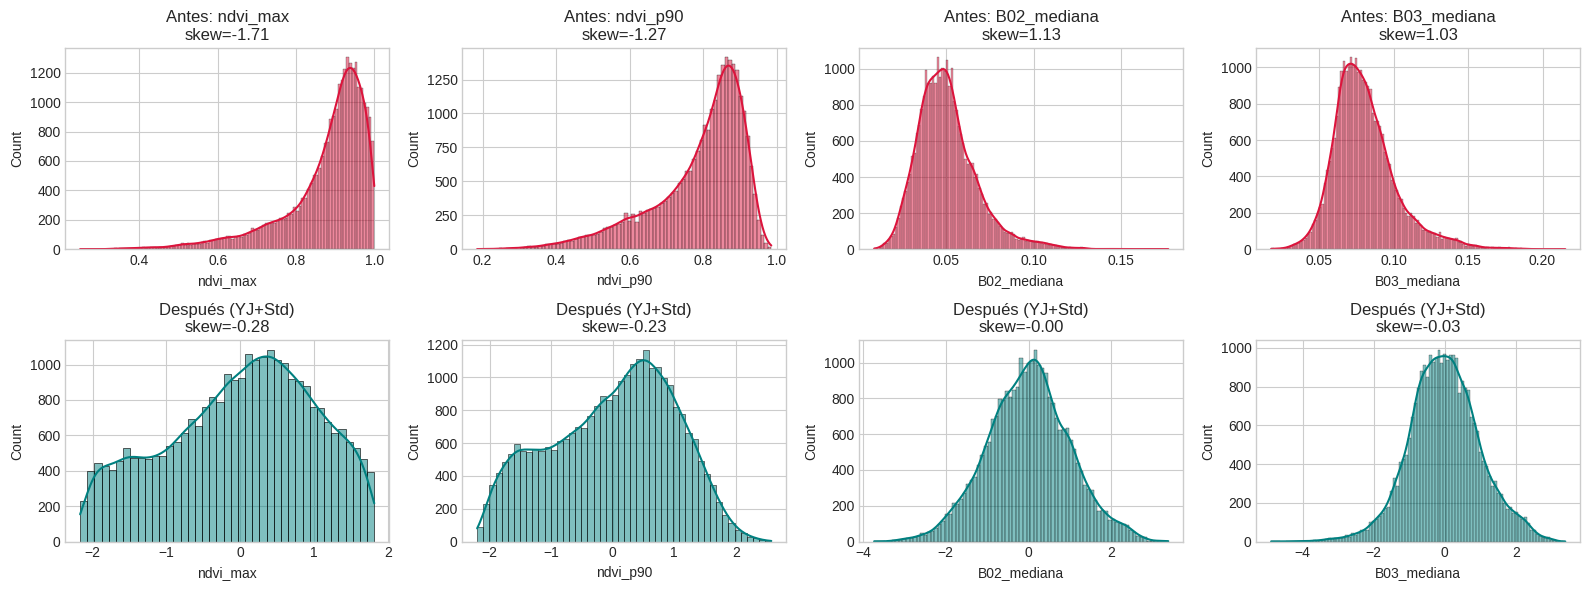

Proporción de valores con |z|>4 por característica (top 5):


,%
ndvi_amplitud,0.33
B11_mediana,0.16
B05_mediana,0.14
B04_mediana,0.06
B03_mediana,0.06


In [ ]:
# ==============================================================================
# B. TRANSFORMACIÓN DE ASIMETRÍA (Yeo-Johnson) + ESTANDARIZACIÓN  (fit en train)
# ==============================================================================
skew_antes = D['train'][COLS_VAR].skew()
COLS_YJ = skew_antes[skew_antes.abs() > UMBRAL_SKEW].index.tolist()
print(f"Variables con |asimetría| > {UMBRAL_SKEW}: {len(COLS_YJ)} de {len(COLS_VAR)}")

T_ = {s: D[s][COLS_VAR].copy() for s in SPLITS}
pt = PowerTransformer(method='yeo-johnson', standardize=False)
if COLS_YJ:
    pt.fit(T_['train'][COLS_YJ])
    for s in SPLITS:
        T_[s][COLS_YJ] = pt.transform(T_[s][COLS_YJ])

scaler = StandardScaler().fit(T_['train'])
Z = {s: pd.DataFrame(scaler.transform(T_[s]), columns=COLS_VAR, index=T_[s].index) for s in SPLITS}

skew_tab = pd.DataFrame({'skew_antes': skew_antes, 'skew_despues': Z['train'].skew(),
                         'yeo_johnson': [c in COLS_YJ for c in COLS_VAR]}, index=COLS_VAR)
display(skew_tab.sort_values('skew_antes', key=np.abs, ascending=False).round(2).head(12))

# Comparación visual antes vs después (las 4 variables más asimétricas)
top4 = skew_antes.abs().sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for j, c in enumerate(top4):
    sns.histplot(D['train'][c], ax=axes[0, j], kde=True, color='crimson'); axes[0, j].set_title(f"Antes: {c}\nskew={skew_antes[c]:.2f}")
    sns.histplot(Z['train'][c], ax=axes[1, j], kde=True, color='teal'); axes[1, j].set_title(f"Después (YJ+Std)\nskew={Z['train'][c].skew():.2f}")
plt.tight_layout(); plt.show()

z_abs = Z['train'].abs()
print("Proporción de valores con |z|>4 por característica (top 5):")
display((z_abs.gt(4).mean() * 100).round(2).sort_values(ascending=False).head(5).to_frame('%'))

In [ ]:
# ==============================================================================
# C. ESTADÍSTICAS POR BANDA (para normalizar tensores crudos en modelos profundos)
# ==============================================================================
def estadisticas_bandas(ids, paso=4, max_parches=200):
    # Media y desviación por banda, acumuladas en GPU, submuestreando el espacio cada `paso` píxeles
    suma = torch.zeros(len(BANDAS), dtype=torch.float64, device=DEVICE)
    suma2 = torch.zeros_like(suma); n = 0
    for pid in tqdm(ids[:max_parches], desc="Estadísticas por banda"):
        a = np.load(s2_dict[pid], mmap_mode='r')[:, :, ::paso, ::paso]
        x = torch.from_numpy(np.asarray(a, dtype=np.float32)).to(DEVICE) / 10000.0     # (T, 10, h, w)
        x = x.permute(1, 0, 2, 3).reshape(len(BANDAS), -1)
        x = x[:, (x > 0).all(dim=0)].double()                                         # excluir no-data
        suma += x.sum(1); suma2 += (x ** 2).sum(1); n += x.shape[1]
    media = suma / n
    std = torch.sqrt(suma2 / n - media ** 2)
    return media.cpu().numpy(), std.cpu().numpy()

banda_media, banda_std = estadisticas_bandas(ids_muestra['train'])
display(pd.DataFrame({'media': banda_media, 'std': banda_std}, index=BANDAS).round(4).T)

Estadísticas por banda:   0%|          | 0/120 [00:00<?, ?it/s]

,B02,B03,B04,B05,B06,B07,B08,B8A,B11,B12
media,0.1234,0.1455,0.1515,0.1860,0.2815,0.3151,0.3300,0.3412,0.2548,0.1744
std,0.1862,0.1785,0.1867,0.1749,0.1595,0.1597,0.1598,0.1581,0.1249,0.1115


## 4. Selección y extracción de características

Cada paso **se apoya en el resultado del anterior** (flujo de filtrado):

| Paso | Técnica | Pregunta que responde | Criterio de decisión |
|---|---|---|---|
| 1 | Umbral de varianza | ¿Hay variables casi constantes? | Varianza Min-Max < 0.005 |
| 2 | ANOVA F-test (+ $\eta^2$) | ¿Cuán discriminante es cada variable respecto a la clase? | Ranking de F |
| 3 | Correlación guiada por ANOVA | ¿Cuáles son redundantes? | $|r| > 0.90$: se conserva la de mayor F |
| 4 | $\chi^2$ y Cramér's V | ¿Aportan las categóricas/discretizadas? | $V \geq 0.10$ |
| 5 | Selección de *k* por validación | ¿Cuántas variables bastan? | Menor *k* a ≤ 0.01 de F1 máximo en validación |
| 6 | PCA | ¿Se puede comprimir aún más? | 95 % de varianza explicada |

> Con muchas observaciones, los *p-values* del ANOVA tienden a 0 aunque el efecto sea pequeño. Por eso se reporta también el tamaño del efecto ($\eta^2$) y se **valida empíricamente** con un modelo.

,caracteristica,F,p_value,eta2
0,ndvi_T2,1320.5733,0.0,0.4468
1,ndvi_T4,1239.0981,0.0,0.4311
2,ndre_std,1066.8456,0.0,0.3949
3,ndmi_std,1035.1266,0.0,0.3877
4,ndvi_p10,1024.9212,0.0,0.3853
5,ndvi_std,1012.2104,0.0,0.3824
6,nbr_std,1003.4800,0.0,0.3803
7,ndvi_mediana,877.7554,0.0,0.3493
8,evi_mediana,847.5359,0.0,0.3414
9,ndwi_std,802.8350,0.0,0.3293


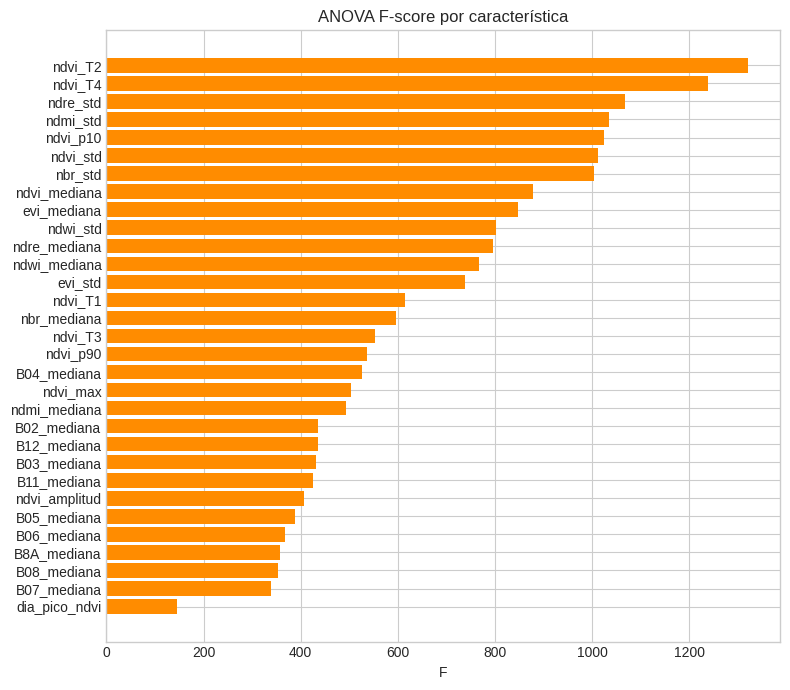

In [ ]:
# ==============================================================================
# 2. ANOVA F-TEST (poder discriminatorio) + tamaño del efecto eta^2
# ==============================================================================
y_tr, y_va, y_te = (D[s]['clase_idx'].values for s in SPLITS)
F, P = f_classif(Z['train'], y_tr)
k_cl, N_tr = len(np.unique(y_tr)), len(y_tr)
eta2 = F * (k_cl - 1) / (F * (k_cl - 1) + (N_tr - k_cl))
anova_tab = (pd.DataFrame({'caracteristica': COLS_VAR, 'F': F, 'p_value': P, 'eta2': eta2})
             .sort_values('F', ascending=False).reset_index(drop=True))
display(anova_tab.round(4).head(10))

plt.figure(figsize=(8, 7)); plt.barh(anova_tab['caracteristica'][::-1], anova_tab['F'][::-1], color='darkorange')
plt.title("ANOVA F-score por característica"); plt.xlabel("F"); plt.tight_layout(); plt.show()

🔹 Tras filtro de correlación (|r| > 0.9): 18 de 31 variables


,eliminada,redundante_con,|r|
0,ndvi_std,ndre_std,0.939
1,nbr_std,ndmi_std,0.969
2,evi_mediana,ndvi_mediana,0.941
3,ndwi_std,ndre_std,0.906
4,ndre_mediana,ndvi_mediana,0.966
5,ndwi_mediana,ndvi_mediana,0.961
6,ndmi_mediana,nbr_mediana,0.960
7,B02_mediana,B04_mediana,0.925
8,B03_mediana,B04_mediana,0.916
9,B05_mediana,B04_mediana,0.902


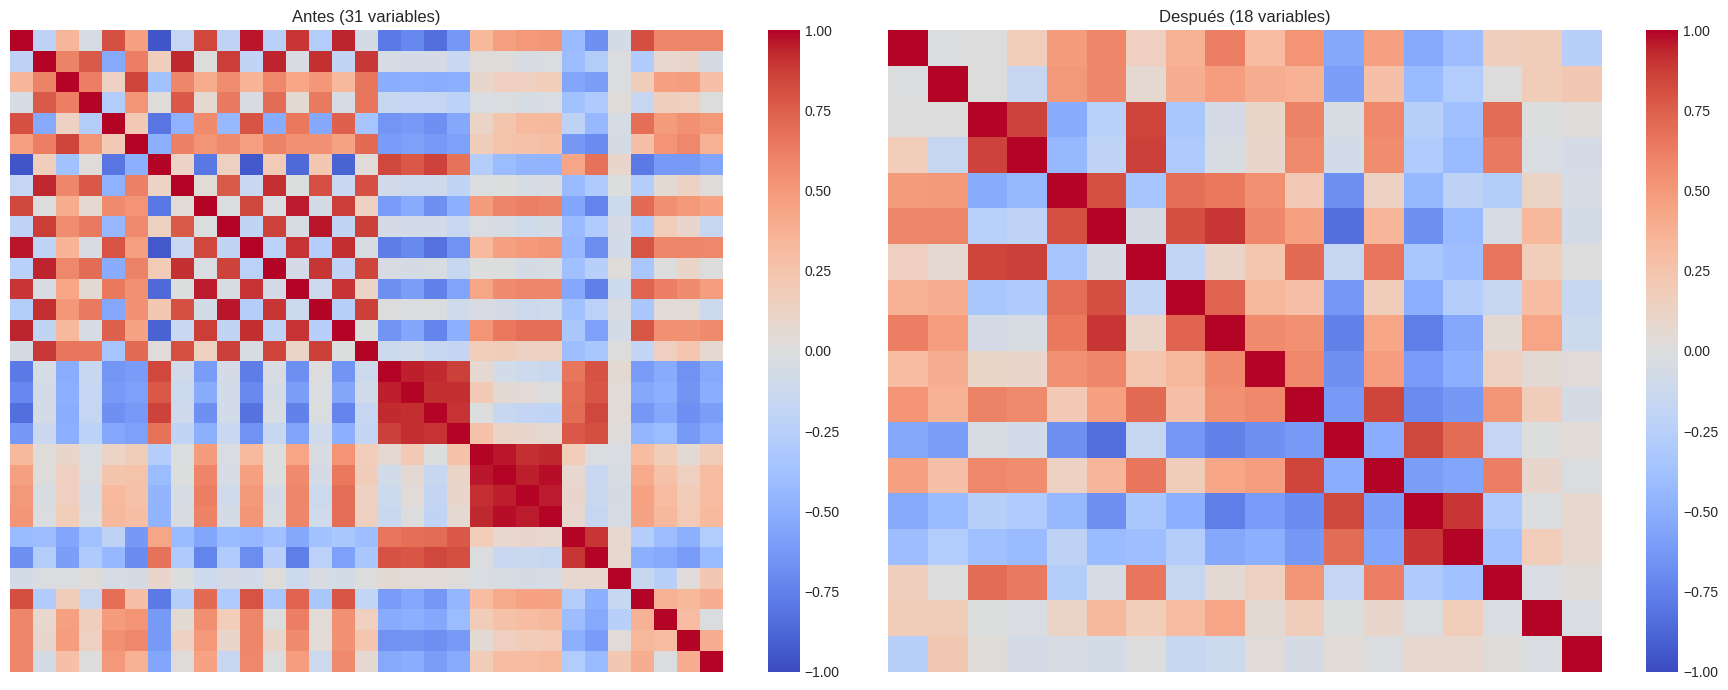

In [ ]:
# ==============================================================================
# 3. CORRELACIÓN GUIADA POR ANOVA: de cada grupo redundante se conserva la de mayor F
# ==============================================================================
corr_abs = Z['train'].corr().abs()
orden_F = anova_tab['caracteristica'].tolist()
conservadas, eliminadas = [], []
for c in orden_F:
    previos = [(k, corr_abs.loc[c, k]) for k in conservadas]
    mejor = max(previos, key=lambda t: t[1]) if previos else None
    if mejor and mejor[1] > UMBRAL_CORR:
        eliminadas.append({'eliminada': c, 'redundante_con': mejor[0], '|r|': round(mejor[1], 3)})
    else:
        conservadas.append(c)
print(f"🔹 Tras filtro de correlación (|r| > {UMBRAL_CORR}): {len(conservadas)} de {len(COLS_VAR)} variables")
display(pd.DataFrame(eliminadas).head(15))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(Z['train'].corr(), cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0], xticklabels=False, yticklabels=False)
axes[0].set_title(f"Antes ({len(COLS_VAR)} variables)")
sns.heatmap(Z['train'][conservadas].corr(), cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1], xticklabels=False, yticklabels=False)
axes[1].set_title(f"Después ({len(conservadas)} variables)")
plt.tight_layout(); plt.show()

In [ ]:
# ==============================================================================
# 4. CATEGÓRICAS / DISCRETIZADAS: chi-cuadrado y V de Cramér frente a la clase
# ==============================================================================
def cramer_v(x, y):
    tabla = pd.crosstab(x, y)
    chi2_, p, _, _ = stats.chi2_contingency(tabla)
    n, k = tabla.values.sum(), min(tabla.shape) - 1
    return chi2_, p, float(np.sqrt(chi2_ / (n * k)))

filas = []
for c in ['estacion_pico'] + COLS_BIN_CAT:
    chi2_, p, v = cramer_v(D['train'][c], D['train']['clase_idx'])
    filas.append({'variable': c, 'chi2': chi2_, 'p_value': p, 'V_cramer': v, 'conservar': v >= UMBRAL_CRAMER})
cat_tab = pd.DataFrame(filas); display(cat_tab.round(4))

# Columnas finales de las categóricas conservadas (ordinales reescaladas a [0,1]; one-hot ya en {0,1})
CAT_CONSERVADAS = cat_tab.loc[cat_tab['conservar'], 'variable'].tolist()
def matriz_cat(s):
    partes = []
    for c in CAT_CONSERVADAS:
        if c == 'estacion_pico': partes.append(D[s][COLS_OHE].values.astype(np.float32))
        else: partes.append((D[s][[c]].values / 2.0).astype(np.float32))        # 3 bins -> {0, .5, 1}
    return np.hstack(partes) if partes else np.empty((len(D[s]), 0), dtype=np.float32)
print("Categóricas conservadas:", CAT_CONSERVADAS)

,variable,chi2,p_value,V_cramer,conservar
0,estacion_pico,10876.2179,0.0,0.3610,True
1,ndvi_mediana_cat,9941.5128,0.0,0.4228,True
2,ndvi_amplitud_cat,5148.9133,0.0,0.3042,True


Categóricas conservadas: ['estacion_pico', 'ndvi_mediana_cat', 'ndvi_amplitud_cat']


In [ ]:
# ==============================================================================
# MODELOS DE VALIDACIÓN: MLP en GPU (pesos de clase) y Random Forest
# ==============================================================================
def sync():
    if DEVICE.type == 'cuda': torch.cuda.synchronize()

def entrenar_mlp(Xtr, ytr, evals, epochs=30, lr=1e-3, bs=512):
    torch.manual_seed(SEED)
    modelo = nn.Sequential(nn.Linear(Xtr.shape[1], 128), nn.ReLU(), nn.Dropout(0.2),
                           nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, N_CLASES)).to(DEVICE)
    cnt = np.bincount(ytr, minlength=N_CLASES).astype(np.float32)
    w = np.where(cnt > 0, len(ytr) / (np.count_nonzero(cnt) * np.maximum(cnt, 1)), 0).astype(np.float32)
    crit = nn.CrossEntropyLoss(weight=torch.tensor(w, device=DEVICE))
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    Xt = torch.tensor(np.asarray(Xtr), dtype=torch.float32, device=DEVICE)
    yt = torch.tensor(ytr, dtype=torch.long, device=DEVICE)
    sync(); t0 = time.time()
    for _ in range(epochs):
        modelo.train(); perm = torch.randperm(len(Xt), device=DEVICE)
        for i in range(0, len(Xt), bs):
            b = perm[i:i + bs]; opt.zero_grad(); crit(modelo(Xt[b]), yt[b]).backward(); opt.step()
    sync(); dur = time.time() - t0
    modelo.eval(); res = []
    with torch.no_grad():
        for X, y in evals:
            pred = modelo(torch.tensor(np.asarray(X), dtype=torch.float32, device=DEVICE)).argmax(1).cpu().numpy()
            res.append((f1_score(y, pred, average='macro'), accuracy_score(y, pred)))
    return res, dur

def entrenar_rf(Xtr, ytr, Xva, yva):
    t0 = time.time()
    rf = RandomForestClassifier(n_estimators=150, n_jobs=-1, class_weight='balanced_subsample', random_state=SEED).fit(Xtr, ytr)
    dur = time.time() - t0
    return f1_score(yva, rf.predict(Xva), average='macro'), dur
print("✅ Funciones de validación definidas")

✅ Funciones de validación definidas


,k,F1_macro_val,accuracy_val
0,2,0.1533,0.1998
1,3,0.2181,0.2790
2,5,0.3233,0.3760
3,8,0.3705,0.4239
4,10,0.4032,0.4521
5,12,0.4181,0.4602
6,15,0.4257,0.4781
7,18,0.4195,0.4831


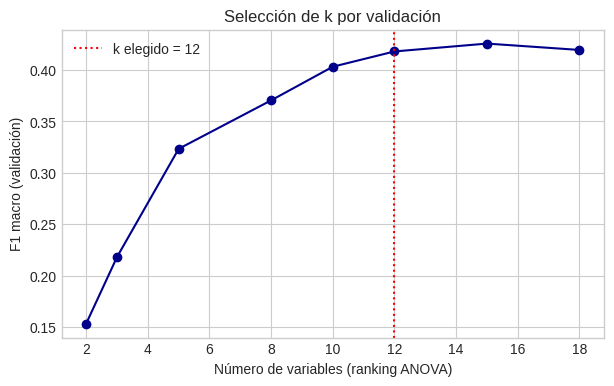

✅ k óptimo = 12  (menor k con F1 ≥ máximo − 0.01)
Variables numéricas seleccionadas: ['ndvi_T2', 'ndvi_T4', 'ndre_std', 'ndmi_std', 'ndvi_p10', 'ndvi_mediana', 'evi_std', 'ndvi_T1', 'nbr_mediana', 'ndvi_T3', 'ndvi_p90', 'B04_mediana']


In [ ]:
# ==============================================================================
# 5. ¿CUÁNTAS VARIABLES BASTAN? Curva F1-macro (validación) vs k, siguiendo el ranking ANOVA
# ==============================================================================
rank_cols = conservadas                     # ya ordenadas por F descendente
grid_k = sorted({k for k in [2, 3, 5, 8, 10, 12, 15, 20, len(rank_cols)] if k <= len(rank_cols)})
curva = []
for k in grid_k:
    cols = rank_cols[:k]
    res, _ = entrenar_mlp(Z['train'][cols].values, y_tr, [(Z['val'][cols].values, y_va)])
    f1, acc = res[0]
    curva.append({'k': k, 'F1_macro_val': f1, 'accuracy_val': acc})
curva = pd.DataFrame(curva); display(curva.round(4))

mejor_f1 = curva['F1_macro_val'].max()
K_OPT = int(curva.loc[curva['F1_macro_val'] >= mejor_f1 - 0.01, 'k'].min())
SEL_NUM = rank_cols[:K_OPT]
plt.figure(figsize=(7, 4)); plt.plot(curva['k'], curva['F1_macro_val'], marker='o', color='darkblue')
plt.axvline(K_OPT, color='red', ls=':', label=f'k elegido = {K_OPT}'); plt.xlabel("Número de variables (ranking ANOVA)")
plt.ylabel("F1 macro (validación)"); plt.title("Selección de k por validación"); plt.legend(); plt.grid(True); plt.show()
print(f"✅ k óptimo = {K_OPT}  (menor k con F1 ≥ máximo − 0.01)")
print("Variables numéricas seleccionadas:", SEL_NUM)

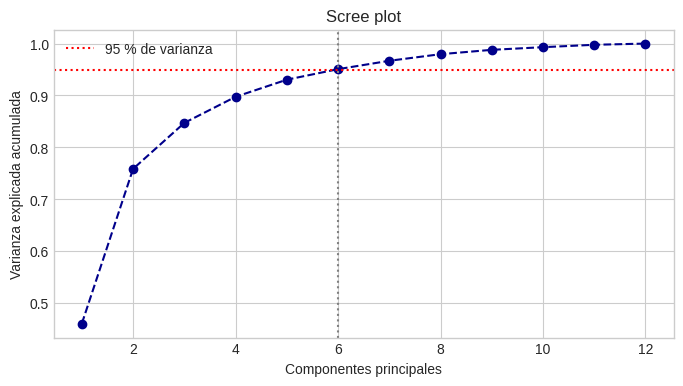

💡 Componentes para 95 % de varianza: 6  (de 12 variables seleccionadas)
Variables con mayor contribución a los 3 primeros componentes (interpretación):
  PC1 (46.1 %): ['ndvi_mediana', 'B04_mediana', 'nbr_mediana', 'ndvi_p10']
  PC2 (29.8 %): ['evi_std', 'ndre_std', 'ndmi_std', 'ndvi_p90']
  PC3 (8.9 %): ['ndvi_T4', 'ndvi_T2', 'ndvi_T3', 'ndre_std']


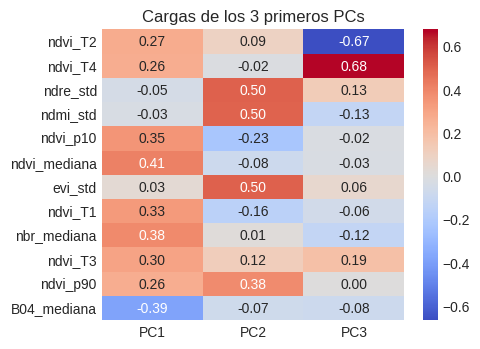

In [ ]:
# ==============================================================================
# 6. EXTRACCIÓN: PCA sobre las variables numéricas seleccionadas (95 % de varianza)
# ==============================================================================
pca_full = PCA().fit(Z['train'][SEL_NUM])
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
N_PCA = int(np.argmax(cum_var >= 0.95) + 1)

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', ls='--', color='darkblue')
plt.axhline(0.95, color='red', ls=':', label='95 % de varianza'); plt.axvline(N_PCA, color='gray', ls=':')
plt.xlabel('Componentes principales'); plt.ylabel('Varianza explicada acumulada'); plt.title('Scree plot'); plt.legend(); plt.grid(True); plt.show()
print(f"💡 Componentes para 95 % de varianza: {N_PCA}  (de {len(SEL_NUM)} variables seleccionadas)")

pca = PCA(n_components=N_PCA).fit(Z['train'][SEL_NUM])
PC = {s: pca.transform(Z[s][SEL_NUM]) for s in SPLITS}
cargas = pd.DataFrame(pca.components_[:3].T, index=SEL_NUM, columns=['PC1', 'PC2', 'PC3'])
print("Variables con mayor contribución a los 3 primeros componentes (interpretación):")
for pc in cargas.columns:
    print(f"  {pc} ({pca.explained_variance_ratio_[int(pc[2:]) - 1] * 100:.1f} %):", cargas[pc].abs().sort_values(ascending=False).head(4).index.tolist())
plt.figure(figsize=(5, max(3, len(SEL_NUM) * 0.3))); sns.heatmap(cargas, cmap='coolwarm', center=0, annot=True, fmt='.2f'); plt.title("Cargas de los 3 primeros PCs"); plt.tight_layout(); plt.show()

## 5. Validación del beneficio de la ingeniería de características
Comparamos cuatro representaciones con el **mismo** MLP (GPU) y un Random Forest. El objetivo no es el mejor modelo, sino comprobar con evidencia que seleccionar/extraer **reduce dimensionalidad y tiempo de entrenamiento sin cuantificar el costo-beneficio** en el desempeño.

,conjunto,n_variables,MLP_F1_val,MLP_F1_test,MLP_t(s),RF_F1_val,RF_t(s)
0,A. Todas las numéricas,31,0.4349,0.4548,2.5891,0.3718,28.6221
1,B. Seleccionadas (filtro),12,0.4181,0.4097,2.8405,0.3673,20.5097
2,C. Seleccionadas + categóricas,18,0.4283,0.4013,2.6951,0.3702,18.4780
3,D. PCA (6 comp.),6,0.3114,0.3108,2.8998,0.3096,14.3813


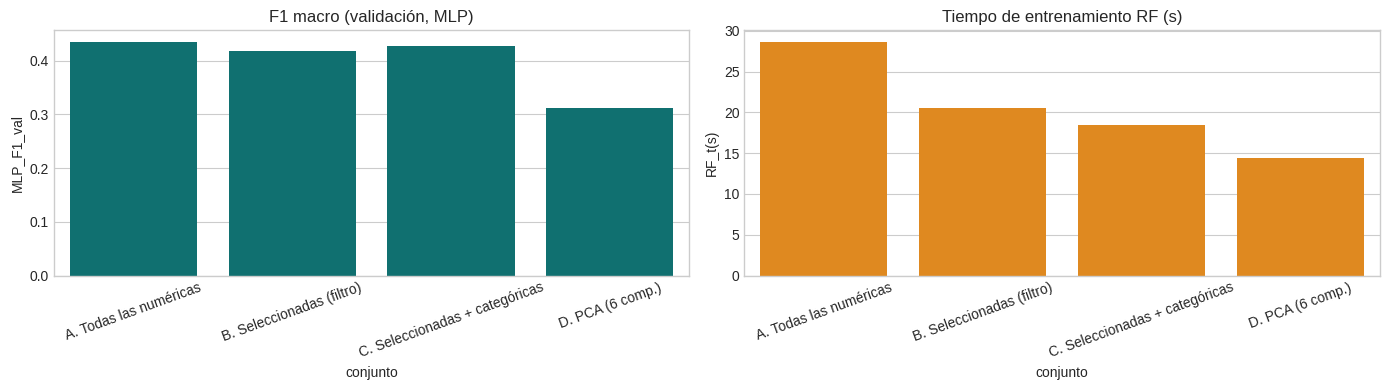

In [ ]:
# ==============================================================================
# COMPARATIVA: todas vs seleccionadas vs seleccionadas+categóricas vs PCA
# ==============================================================================
def X_num(cols, s): return Z[s][cols].values.astype(np.float32)
CONJUNTOS = {
    'A. Todas las numéricas':          {s: X_num(COLS_VAR, s) for s in SPLITS},
    'B. Seleccionadas (filtro)':       {s: X_num(SEL_NUM, s) for s in SPLITS},
    'C. Seleccionadas + categóricas':  {s: np.hstack([X_num(SEL_NUM, s), matriz_cat(s)]) for s in SPLITS},
    f'D. PCA ({N_PCA} comp.)':         {s: PC[s].astype(np.float32) for s in SPLITS},
}
filas = []
for nombre, X in CONJUNTOS.items():
    (r_va, r_te), t_mlp = entrenar_mlp(X['train'], y_tr, [(X['val'], y_va), (X['test'], y_te)])
    f1_rf, t_rf = entrenar_rf(X['train'], y_tr, X['val'], y_va)
    filas.append({'conjunto': nombre, 'n_variables': X['train'].shape[1],
                  'MLP_F1_val': r_va[0], 'MLP_F1_test': r_te[0], 'MLP_t(s)': t_mlp,
                  'RF_F1_val': f1_rf, 'RF_t(s)': t_rf})
comp = pd.DataFrame(filas); display(comp.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=comp, x='conjunto', y='MLP_F1_val', ax=ax[0], color='teal'); ax[0].set_title("F1 macro (validación, MLP)"); ax[0].tick_params(axis='x', rotation=20)
sns.barplot(data=comp, x='conjunto', y='RF_t(s)', ax=ax[1], color='darkorange'); ax[1].set_title("Tiempo de entrenamiento RF (s)"); ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

In [ ]:
SEED_ORIG = SEED
resumen = []
for nombre, X in CONJUNTOS.items():
    mv, mt, rv = [], [], []
    for sd in [42, 7, 123]:
        SEED = sd
        (r_va, r_te), _ = entrenar_mlp(X['train'], y_tr, [(X['val'], y_va), (X['test'], y_te)])
        f1_rf, _ = entrenar_rf(X['train'], y_tr, X['val'], y_va)
        mv.append(r_va[0]); mt.append(r_te[0]); rv.append(f1_rf)
    resumen.append({'conjunto': nombre,
                    'MLP_val': f"{np.mean(mv):.3f} ± {np.std(mv):.3f}",
                    'MLP_test': f"{np.mean(mt):.3f} ± {np.std(mt):.3f}",
                    'RF_val': f"{np.mean(rv):.3f} ± {np.std(rv):.3f}"})
SEED = SEED_ORIG
display(pd.DataFrame(resumen))

,conjunto,MLP_val,MLP_test,RF_val
0,A. Todas las numéricas,0.440 ± 0.004,0.459 ± 0.007,0.374 ± 0.002
1,B. Seleccionadas (filtro),0.415 ± 0.004,0.410 ± 0.000,0.366 ± 0.001
2,C. Seleccionadas + categóricas,0.425 ± 0.003,0.407 ± 0.004,0.367 ± 0.003
3,D. PCA (6 comp.),0.320 ± 0.007,0.318 ± 0.006,0.310 ± 0.001


## 6. Exportación: pipeline ajustado, características y particiones
Para no duplicar los ~27 GB de imágenes, se guardan: (i) las **particiones oficiales** como rutas a los archivos originales, (ii) las **estadísticas por banda** para normalizar tensores en un `DataLoader`, (iii) el **pipeline ajustado** (imputador, discretizador, one-hot, Yeo-Johnson, escalador, PCA, listas de variables) para aplicarlo idéntico en inferencia, y (iv) las tablas de características ya transformadas.

In [ ]:
# ==============================================================================
# EXPORTACIÓN A .PICKLE (metadatos + pipeline) Y TABLAS DE CARACTERÍSTICAS
# ==============================================================================
if HAY_FOLDS:
    folds_oficiales = {f'fold_{k}': {'s2': [s2_dict[i] for i in ids_comunes if fold_de[i] == k],
                                     'target': [target_dict[i] for i in ids_comunes if fold_de[i] == k]}
                       for k in sorted(set(fold_de.values()))}
else:
    folds_oficiales = None

pipeline = {'imputer': imputer, 'kbins': kbd, 'ohe': ohe, 'minmax_varianza': mm, 'yeo_johnson': pt,
            'scaler': scaler, 'pca': pca}
dataset_metadata = {
    'splits': {'folds_oficiales_usados': FOLDS_SPLIT if HAY_FOLDS else 'aleatorio_por_parche',
               'ids_muestreados': ids_muestra},
    'folds': folds_oficiales,
    'norm_bandas': {'bandas': BANDAS, 'mean': banda_media.tolist(), 'std': banda_std.tolist()},
    'features': {'numericas_iniciales': COLS_NUM, 'tras_varianza': COLS_VAR, 'yeo_johnson': COLS_YJ,
                 'tras_correlacion': conservadas, 'seleccionadas': SEL_NUM, 'categoricas': CAT_CONSERVADAS,
                 'k_optimo': int(K_OPT), 'n_componentes_pca': int(N_PCA)},
    'pipeline': pipeline, 'clases': CLASES, 'clase_a_indice': CLASE_A_IDX,
}
with open('pastis_pipeline_metadata.pickle', 'wb') as f:
    pickle.dump(dataset_metadata, f, protocol=pickle.HIGHEST_PROTOCOL)

tablas = {}
for s in SPLITS:
    df = pd.DataFrame(CONJUNTOS['C. Seleccionadas + categóricas'][s],
                      columns=SEL_NUM + [f"cat_{i}" for i in range(CONJUNTOS['C. Seleccionadas + categóricas'][s].shape[1] - len(SEL_NUM))])
    df['clase_idx'] = D[s]['clase_idx'].values; df['patch_id'] = D[s]['patch_id'].values
    for j in range(N_PCA): df[f'PC{j + 1}'] = PC[s][:, j]
    tablas[s] = df
with open('pastis_features_fe.pickle', 'wb') as f:
    pickle.dump(tablas, f, protocol=pickle.HIGHEST_PROTOCOL)

for nom in ['pastis_pipeline_metadata.pickle', 'pastis_features_fe.pickle']:
    print(f"📦 {nom}: {os.path.getsize(nom) / 1024**2:.2f} MB")

📦 pastis_pipeline_metadata.pickle: 0.01 MB
📦 pastis_features_fe.pickle: 4.84 MB


In [ ]:
# ==============================================================================
# 7. CONCLUSIONES CRISP-ML(Q) — con las cifras reales de esta ejecución
# ==============================================================================
A, B, C_, Dp = (comp.iloc[i] for i in range(4))
red_vars = (1 - B['n_variables'] / A['n_variables']) * 100
red_pca = (1 - Dp['n_variables'] / A['n_variables']) * 100
acel_rf = A['RF_t(s)'] / max(B['RF_t(s)'], 1e-9)
n_est_rows = {s: len(D[s]) for s in SPLITS}
cat_txt = ", ".join(CAT_CONSERVADAS) if CAT_CONSERVADAS else "ninguna alcanzó V ≥ 0.10"

Markdown(f'''
### Resultados cuantitativos de la fase
- **Datos:** {n_est_rows['train']:,} / {n_est_rows['val']:,} / {n_est_rows['test']:,} píxeles (train/val/test) de {sum(len(v) for v in ids_muestra.values())} parches, con particiones {'por folds oficiales' if HAY_FOLDS else 'aleatorias por parche'}.
- **Construcción:** {len(COLS_NUM)} características numéricas (6 índices, estadísticos robustos, fenología, 10 bandas) + categóricas (`estacion_pico`, discretizaciones por cuantiles).
- **Normalización:** {len(COLS_YJ)} de {len(COLS_VAR)} variables con |asimetría| > {UMBRAL_SKEW} transformadas con Yeo-Johnson; estandarización de todas.
- **Selección:** varianza → {len(COLS_VAR)}; correlación guiada por ANOVA → {len(conservadas)}; *k* óptimo por validación → **{K_OPT}** ({red_vars:.0f} % menos variables que las {int(A['n_variables'])} iniciales). Categóricas conservadas: {cat_txt}.
- **Extracción:** PCA con **{N_PCA}** componentes explica ≥ 95 % de la varianza ({red_pca:.0f} % de reducción).
- **Validación (F1 macro, validación/MLP):** todas = {A['MLP_F1_val']:.3f}, seleccionadas = {B['MLP_F1_val']:.3f}, +categóricas = {C_['MLP_F1_val']:.3f}, PCA = {Dp['MLP_F1_val']:.3f}. Tiempo de Random Forest: {A['RF_t(s)']:.1f} s → {B['RF_t(s)']:.1f} s (x{acel_rf:.1f}).
''')


### Resultados cuantitativos de la fase
- **Datos:** 27,813 / 8,473 / 8,990 píxeles (train/val/test) de 200 parches, con particiones aleatorias por parche.
- **Construcción:** 32 características numéricas (6 índices, estadísticos robustos, fenología, 10 bandas) + categóricas (`estacion_pico`, discretizaciones por cuantiles).
- **Normalización:** 6 de 31 variables con |asimetría| > 0.75 transformadas con Yeo-Johnson; estandarización de todas.
- **Selección:** varianza → 31; correlación guiada por ANOVA → 18; *k* óptimo por validación → **12** (61 % menos variables que las 31 iniciales). Categóricas conservadas: estacion_pico, ndvi_mediana_cat, ndvi_amplitud_cat.
- **Extracción:** PCA con **6** componentes explica ≥ 95 % de la varianza (81 % de reducción).
- **Validación (F1 macro, validación/MLP):** todas = 0.435, seleccionadas = 0.418, +categóricas = 0.428, PCA = 0.311. Tiempo de Random Forest: 28.6 s → 20.5 s (x1.4).


### Conclusión general en el contexto de CRISP-ML(Q) — fase *Data Preparation*

1. **Selección y limpieza de datos.** Se descartaron las clases no agrícolas (Background y Void), las observaciones sin dato o nubosas (B02 > 0.25) y los píxeles con menos de 5 observaciones válidas. Los índices espectrales se acotaron a su rango físico [-1, 1], lo que corrige los valores imposibles de NDVI y NDWI detectados al explorar los datos. Se muestrearon 200 parches (120/40/40) con hasta 40 píxeles por clase y parche, para que las clases minoritarias no quedaran diluidas.

2. **Ingeniería de características guiada por el dominio.** Se construyeron 32 características: seis índices (NDVI, EVI, NDRE, NDMI, NBR, NDWI), estadísticos robustos a nubes (mediana, percentiles, desviación, amplitud), las 10 bandas y descriptores fenológicos. Como el dataset no incluye las fechas de adquisición, los descriptores estacionales se calcularon sobre cuartiles de la serie temporal (T1–T4) y no por estación del año. La codificación se adaptó al tipo de variable: ordinal por cuantiles para las discretizaciones, one-hot para la categoría nominal `estacion_pico` y etiqueta contigua 0–17 para la clase.

3. **Normalización.** 6 de 31 variables presentaron |asimetría| > 0.75 y se transformaron con Yeo-Johnson, que admite valores negativos. Después se estandarizaron todas, de modo que ninguna domina por magnitud, lo cual beneficia a PCA, al ANOVA y al entrenamiento por gradiente. Imputador, discretizador, transformadores y escalador se ajustaron solo con entrenamiento. Se calcularon además media y desviación por banda para normalizar tensores crudos en un DataLoader.

4. **Selección y extracción, con evidencia.** El flujo fue: varianza (31 de 32 variables; [escribe aquí la variable descartada]) → correlación guiada por ANOVA (18) → selección de k por validación (12, una reducción de 61 %). Se repitió la evaluación con tres semillas (media ± desviación):
   - Con **Random Forest**, la selección mantuvo casi todo el desempeño (F1 macro 0.374 → 0.366, ~1 punto) y redujo el tiempo de entrenamiento en ~28 %.
   - Con **MLP**, la selección sí tuvo costo: 0.440 → 0.415 en validación y 0.459 → 0.410 en prueba, con desviaciones menores a 0.01, es decir, una pérdida consistente.
   - Las **categóricas** (V de Cramér entre 0.35 y 0.84) no mejoraron de forma consistente el desempeño (MLP val 0.415 → 0.425, test 0.410 → 0.407), por lo que se conservan por su asociación con la clase y no por su efecto en el modelo.
   - **PCA** (6 componentes, 95 % de varianza) degradó el desempeño en ambos modelos (F1 ≈ 0.31–0.32). Conservar varianza no equivale a conservar poder discriminante, por lo que no se recomienda como entrada del clasificador.
   En conjunto, la selección es útil para reducir redundancia, interpretar y acelerar modelos de árboles, pero con redes neuronales la representación completa rinde mejor.

5. **Aseguramiento de calidad (la "Q" de CRISP-ML(Q)).** Se evitó la fuga de datos ajustando todos los transformadores solo con entrenamiento y particionando por parche, nunca por píxel. Se fijaron semillas, se verificaron los rangos físicos, se usaron pesos de clase por el desbalance y se exportó el pipeline ajustado para aplicarlo idéntico en inferencia.

6. **Riesgos y limitaciones.** (i) La partición es aleatoria por parche porque el dataset no incluye los folds oficiales de PASTIS, que están separados espacialmente; esto puede dar resultados algo optimistas. (ii) Sin fechas de adquisición, la fenología es aproximada. (iii) Se usó una fracción de los parches y la comparativa varió solo la semilla del modelo, no el muestreo. (iv) El umbral de nubes es una heurística, sin máscara de nubes. (v) El F1 macro absoluto (~0.4) refleja clasificación píxel a píxel con variables tabulares y 18 clases desbalanceadas; sirve para comparar representaciones, no como desempeño del modelo final.

7. **Siguiente fase (*Baseline*).** Se usará la representación completa de 31 variables como línea base de mayor desempeño, y el conjunto de 12 o 18 variables como alternativa compacta e interpretable. Para evaluar con rigor se emplearán folds espacialmente separados, y los modelos que aprovechen la serie temporal completa y el contexto espacial deberían superar este referente tabular.